# Notebook 2 of 2 — Pretrained GridSFM feasibility predictions + bus-level SHAP

**Run this after Notebook 1 (`01_gaussian_load_sampling.ipynb`).** It reads the saved Gaussian load scenarios and uses **only the pretrained GridSFM model** to predict whether each scenario is feasible or infeasible.

- This notebook **never calls Julia** and **never uses Julia's accepted/rejected label as the model verdict**.
- Select a scenario easily using a filter/dropdown based on **GridSFM's predicted probability** (or set a manual index).
- Captum Kernel SHAP explains **which load groups and selected buses' Pd/Qd perturbations** raised or lowered `P(feasible)` or `P(infeasible)`.
- Bus results include bus ID, name, active load IDs and individual Pd/Qd contributions. Their meaning is **model attribution**, not a physical proof of AC-OPF infeasibility.

**Workflow:** execute sections 1–5, choose a candidate in section 6, then run the explanation and export cells. A confirmed matching PyG graph and pretrained checkpoint are required; there is **no placeholder model**.


## 1. Dataset, saved sampling file, and output location

Uses the standardized sampling folder first. The old nested folder is only a fallback to support archives created by your previous notebook. If multiple archives exist, the first matching candidate is selected; set `SCENARIO_PATH_OVERRIDE` if necessary.

In [1]:
import csv
import hashlib
import json
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

DATASET_NAME = "alabama"   # Must match your sampling notebook
TIME_SLICE = "16h"
DATASET_LABEL = DATASET_NAME.replace("_", " ").title()
SCENARIO_PATH_OVERRIDE = None  # e.g. Path("/path/to/acopf_labeled_scenarios.npz")

def find_project_root():
    cwd = Path.cwd().resolve()
    for parent in (cwd, *cwd.parents):
        for candidate in (parent, parent / "GridSFM"):
            if (candidate / "model").is_dir() and (candidate / "verifier").is_dir():
                return candidate
    raise FileNotFoundError("Cannot find GridSFM root (expected model/ and verifier/). Run inside the repository.")

PROJECT_ROOT = find_project_root()
MODEL_DIR = PROJECT_ROOT / "model"
GRID_DATA_ROOT = next((p for p in [PROJECT_ROOT / "power_grid", PROJECT_ROOT.parent / "power_grid"]
                       if (p / "US" / "gridsfm_data").is_dir()), None)
if GRID_DATA_ROOT is None:
    raise FileNotFoundError("Missing power_grid/US/gridsfm_data under GridSFM/ or its parent")
DATA_DIR = GRID_DATA_ROOT / "US" / "gridsfm_data" / TIME_SLICE
DATA_PATH = DATA_DIR / f"{DATASET_NAME}_model.json"

# Prefer the output of Notebook 1; support your legacy nested output as fallback.
SCENARIO_CANDIDATES = [
    PROJECT_ROOT / "results" / "gaussian_load_centered" / DATASET_NAME / "acopf_labeled_scenarios.npz",
    PROJECT_ROOT / "results" / "gaussian_load_centered" / "results" / "gaussian_voltage_squeeze" / DATASET_NAME / "acopf_labeled_scenarios.npz",
]
if SCENARIO_PATH_OVERRIDE is None:
    existing = [p for p in SCENARIO_CANDIDATES if p.is_file()]
    if not existing:
        raise FileNotFoundError("No sampled candidates found. Run the attached Gaussian sampling notebook first. "
                                f"Looked at: {[str(p) for p in SCENARIO_CANDIDATES]}")
    SCENARIO_PATH = existing[0]
    if len(existing) > 1:
        print("NOTE: Multiple candidate archives found; using first (the standardized Notebook 1 output).")
        for f in existing: print("  ", f)
else:
    SCENARIO_PATH = Path(SCENARIO_PATH_OVERRIDE).expanduser().resolve()

assert DATA_PATH.is_file(), f"Raw grid case missing: {DATA_PATH}"
assert SCENARIO_PATH.is_file(), f"Scenario file missing: {SCENARIO_PATH}"
with DATA_PATH.open("r", encoding="utf-8") as f:
    data = json.load(f)
assert isinstance(data.get("load"), dict) and isinstance(data.get("bus"), dict)
CASE_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
load_ids = [str(key) for key, val in data["load"].items() if int(val.get("status", 1)) == 1]
loads = np.asarray([[float(data["load"][lid]["pd"]), float(data["load"][lid]["qd"])]
                    for lid in load_ids], dtype=np.float32)
n_loads = len(load_ids)
n_buses = len(data["bus"])
assert n_loads > 0 and np.isfinite(loads).all()
EXPLAIN_ROOT = SCENARIO_PATH.parent / "gridsfm_pretrained_bus_shap"
EXPLAIN_ROOT.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATASET_NAME, "| buses:", n_buses, "| active loads:", n_loads)
print("Saved samples:", SCENARIO_PATH)
print("SHAP results:", EXPLAIN_ROOT)

NOTE: Multiple candidate archives found; using first (the standardized Notebook 1 output).
   /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_load_centered/alabama/acopf_labeled_scenarios.npz
   /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_load_centered/results/gaussian_voltage_squeeze/alabama/acopf_labeled_scenarios.npz
Project root: /Users/punrong_rany/Desktop/Projects/GridSFM
Dataset: alabama | buses: 494 | active loads: 494
Saved samples: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_load_centered/alabama/acopf_labeled_scenarios.npz
SHAP results: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_load_centered/alabama/gridsfm_pretrained_bus_shap


## 2. Load the actual pretrained GridSFM checkpoint and matching PyG graph

This notebook imports `gridsfm` from your repository. It **does not train a surrogate**. Ensure the same Python environment has `torch`, `torch_geometric`, `captum`, and your GridSFM dependencies installed. If the checkpoint or PyG file is elsewhere, set the override paths.

In [2]:
# Install dependencies in the GridSFM/model environment if missing.
# From a terminal inside GridSFM/model: python -m pip install -e . captum
import sys
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))

import torch
from captum.attr import KernelShap, FeatureAblation
from gridsfm import load_model, load_pyg_json, prepare_for_inference, predict

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Override either path if your installation stores them elsewhere.
CHECKPOINT_PATH_OVERRIDE = None  # e.g. Path("/path/to/gridsfm_open_v1.1.pt")
PYG_PATH_OVERRIDE = None         # e.g. Path("/path/to/texas_model.pyg.json")
CHECKPOINT_CANDIDATES = [
    MODEL_DIR / "checkpoints" / "gridsfm_open_v1.1.pt",
]
PYG_CANDIDATES = [
    DATA_DIR / f"{DATASET_NAME}_model.pyg.json",
    (GRID_DATA_ROOT / "US" / "topology_solver_pipeline" / "output"
        / f"{DATASET_NAME}_{TIME_SLICE}" / f"{DATASET_NAME}_model.pyg.json"),
    MODEL_DIR / "samples" / f"msr_{DATASET_NAME}.pyg.json",
]

def first_existing(paths, label):
    result = next((p.resolve() for p in paths if p.is_file()), None)
    if result is None:
        raise FileNotFoundError(
            f"Cannot locate {label} for {DATASET_LABEL}. Checked: {[str(p) for p in paths]}. "
            "Supply an explicit *_PATH_OVERRIDE if needed.")
    return result

CHECKPOINT_PATH = first_existing(
    [Path(CHECKPOINT_PATH_OVERRIDE)] if CHECKPOINT_PATH_OVERRIDE is not None
    else CHECKPOINT_CANDIDATES,
    "GridSFM checkpoint")
PYG_PATH = first_existing(
    [Path(PYG_PATH_OVERRIDE)] if PYG_PATH_OVERRIDE is not None
    else PYG_CANDIDATES,
    "PyG graph")

print("Device:", DEVICE)
print("Checkpoint:", CHECKPOINT_PATH)
print("PyG graph:", PYG_PATH)

grid_model = load_model(str(CHECKPOINT_PATH), device=str(DEVICE))
grid_model.eval()
for parameter in grid_model.parameters():
    parameter.requires_grad_(False)
print("Pretrained GridSFM-Open loaded (NO surrogate training).")


/Users/punrong_rany/Desktop/Projects/GridSFM/model/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu
Checkpoint: /Users/punrong_rany/Desktop/Projects/GridSFM/model/checkpoints/gridsfm_open_v1.1.pt
PyG graph: /Users/punrong_rany/Desktop/Projects/GridSFM/power_grid/US/topology_solver_pipeline/output/alabama_16h/alabama_model.pyg.json
Pretrained GridSFM-Open loaded (NO surrogate training).


## 3. Validate load ↔ PyG ↔ bus mapping

**Do not skip this.** A SHAP ranking would be misleading if a candidate's load rows are applied to the wrong PyG loads/buses. We verify active load values and each load's bus reference before inference.

In [3]:
raw_graph = load_pyg_json(PYG_PATH)  # UNPREPARED PyG graph
with PYG_PATH.open("r", encoding="utf-8") as f:
    pyg_metadata = json.load(f).get("metadata", {})

# Optional mapping overrides: exact original IDs in PyG row order, if needed.
PYG_LOAD_ID_ORDER = None  # e.g. ["1", "2", "3", ...]
PYG_BUS_ID_ORDER = None   # e.g. ["101", "102", ...] for all PyG bus rows

n_pyg_loads = int(raw_graph["load"].x.shape[0])
assert n_pyg_loads == n_loads, (
    f"Raw case has {n_loads} active loads, but PyG has {n_pyg_loads}. "
    "The graph may include inactive loads, or not represent the same raw case."
)

def numerical_id_sort(ids):
    try:
        return sorted(ids, key=lambda item: int(item))
    except ValueError:
        return sorted(ids)

metadata_load_ids = pyg_metadata.get("load_id_map")
if PYG_LOAD_ID_ORDER is not None:
    pyg_load_ids = [str(v) for v in PYG_LOAD_ID_ORDER]
    load_mapping_source = "manual override"
elif isinstance(metadata_load_ids, list) and len(metadata_load_ids) == n_loads:
    pyg_load_ids = [str(v) for v in metadata_load_ids]
    load_mapping_source = "metadata.load_id_map list"
else:
    pyg_load_ids = numerical_id_sort(load_ids)
    load_mapping_source = "numerically sorted load IDs (validated candidate)"

assert len(pyg_load_ids) == n_loads and len(set(pyg_load_ids)) == n_loads, (
    "PyG load ID order must list each load exactly once.")
assert set(pyg_load_ids) == set(load_ids), (
    "PyG load ID order does not match the active raw-case IDs. Set PYG_LOAD_ID_ORDER.")
load_index = {lid: i for i, lid in enumerate(load_ids)}
pyg_to_notebook_index = np.asarray([load_index[lid] for lid in pyg_load_ids], dtype=int)
pyg_original_loads = loads[pyg_to_notebook_index].astype(np.float32)
np.testing.assert_allclose(
    pyg_original_loads,
    raw_graph["load"].x[:, :2].detach().cpu().numpy(),
    rtol=1e-5, atol=2e-6,
    err_msg=("Raw-to-PyG Pd/Qd rows do not match. Confirm graph and dataset; "
             "set PYG_LOAD_ID_ORDER if the PyG row order is different.")
)

n_pyg_buses = int(raw_graph["bus"].x.shape[0])
bus_id_map = PYG_BUS_ID_ORDER if PYG_BUS_ID_ORDER is not None else pyg_metadata.get("bus_id_map")
assert isinstance(bus_id_map, list) and len(bus_id_map) == n_pyg_buses, (
    "Need a list of original bus IDs in PyG order. Missing/invalid metadata.bus_id_map; "
    "set PYG_BUS_ID_ORDER after verifying its exact row mapping."
)
l2b = raw_graph[("load", "load_link", "bus")].edge_index.detach().cpu().numpy()
assert l2b.shape[0] == 2 and l2b.shape[1] == n_loads, (
    "Expected exactly one load-to-bus edge per active load.")
assert (l2b[0] >= 0).all() and (l2b[0] < n_loads).all() and np.unique(l2b[0]).size == n_loads, (
    "Load-link edges must enumerate every PyG load exactly once.")
assert (l2b[1] >= 0).all() and (l2b[1] < n_pyg_buses).all()
pyg_load_bus_idx = np.full(n_loads, -1, dtype=int)
pyg_load_bus_idx[l2b[0]] = l2b[1]
pyg_load_bus_id = [str(bus_id_map[j]) for j in pyg_load_bus_idx]

for lid, busid in zip(pyg_load_ids, pyg_load_bus_id):
    raw_bus = str(data["load"][lid]["load_bus"])
    assert raw_bus == busid or (
        raw_bus.lstrip("0") == busid.lstrip("0")
    ), (f"Load {lid}: raw bus {raw_bus} does not match PyG bus {busid}. "
        "Check PYG_LOAD_ID_ORDER, PYG_BUS_ID_ORDER and PYG_PATH.")
    assert busid in data["bus"], f"Bus {busid} not in the selected raw case."

# Longitude-based grouping is used when every load's bus has a valid longitude.
# Otherwise, use non-geographic graph-row groups and label them transparently.
try:
    longitudes = np.asarray([float(data["bus"][b]["lon"]) for b in pyg_load_bus_id])
    if not np.isfinite(longitudes).all():
        raise ValueError("Nonfinite longitude")
    GROUPING_METHOD = "longitude_rank_quantiles"
    GROUP_LABEL = "Band"
except (KeyError, TypeError, ValueError):
    longitudes = None
    GROUPING_METHOD = "pyg_load_row_groups_non_geographic"
    GROUP_LABEL = "Group"
    print("WARNING: longitude unavailable; using non-geographic PyG load-row groups for SHAP.")

print("MATCH:", n_loads, DATASET_LABEL, "loads and bus references align with PyG.")
print("Load mapping source:", load_mapping_source)
print("Grouping:", GROUPING_METHOD)
print("Example PyG row 0: load ID", pyg_load_ids[0], "bus", pyg_load_bus_id[0])


MATCH: 494 Alabama loads and bus references align with PyG.
Load mapping source: metadata.load_id_map list
Grouping: longitude_rank_quantiles
Example PyG row 0: load ID 1 bus 9


## 4. Load candidates from Notebook 1 — ignore Julia verdicts

`candidates` contains the absolute `[Pd, Qd]` matrices. We check the original case fingerprint and exact load-ID order. The saved Julia outcomes are intentionally not read; **pretrained GridSFM supplies the verdicts and SHAP target**.

In [4]:
with np.load(SCENARIO_PATH, allow_pickle=False) as saved:
    candidates = saved["candidates"].astype(np.float32)
    saved_ids = saved["load_ids"].astype(str)
    saved_iteration = (saved["iteration"].astype(int) if "iteration" in saved.files
                       else np.zeros(len(candidates), dtype=int))
    saved_scenario = (saved["scenario"].astype(int) if "scenario" in saved.files
                      else np.arange(1, len(candidates) + 1))
    saved_name = str(saved["dataset_name"].item()) if "dataset_name" in saved.files else None
    saved_sha = (str(saved["source_case_sha256"].item())
                 if "source_case_sha256" in saved.files else None)

assert saved_name == DATASET_NAME, f"Saved dataset {saved_name} != {DATASET_NAME}"
assert saved_sha == CASE_SHA256, "Source grid case changed. Use the exact case sampled by Notebook 1."
assert np.array_equal(saved_ids, np.asarray(load_ids, dtype=str)), "Load order mismatch between saved NPZ and raw case."
assert candidates.ndim == 3 and candidates.shape[1:] == loads.shape and len(candidates) > 0
assert np.isfinite(candidates).all()
assert len(saved_iteration) == len(candidates) == len(saved_scenario)
print(f"Loaded {len(candidates)} scenarios, each with {n_loads} [Pd, Qd] pairs.")
print("Sampling stops here: NO Julia calls or Julia verdicts are used below.")

Loaded 20 scenarios, each with 494 [Pd, Qd] pairs.
Sampling stops here: NO Julia calls or Julia verdicts are used below.


## 5. Pretrained GridSFM inference (not Julia)

The original graph topology stays fixed, and load features are replaced per candidate. Matching raw-case load IDs and PyG row order is essential. Model probabilities are predictions—not optimization certificates.

In [5]:
original = pyg_original_loads.copy()   # Validated PyG row order
def grid_probability_pygrid(pyg_load_array):
    vals = np.asarray(pyg_load_array, dtype=np.float32)
    if vals.shape != original.shape or not np.isfinite(vals).all():
        raise ValueError(f"Invalid load input {vals.shape}, expected {original.shape}.")
    # Original raw graph: topology and non-load features never change.
    g = raw_graph.clone()
    g["load"].x[:, :2] = torch.from_numpy(vals.copy())
    prepare_for_inference(g)  # Recompute DC prior features and g_ctx for these exact loads!
    g = g.to(DEVICE)
    with torch.no_grad():
        predicted = grid_model(g)
        p = torch.sigmoid(predicted.feas_logit).reshape(-1)
    return float(p[0].detach().cpu())


# Separate scalar target wrapper for SHAP; choose target only after candidate selection.
class LoadFeasibilityProbability(torch.nn.Module):
    def __init__(self, target="feasible"):
        super().__init__()
        if target not in ("feasible", "infeasible"):
            raise ValueError(target)
        self.target = target

    def forward(self, batch_loads):
        values = batch_loads.detach().cpu().numpy()
        p_feasible = np.asarray([grid_probability_pygrid(row) for row in values], dtype=np.float32)
        targets = p_feasible if self.target == "feasible" else (1.0 - p_feasible)
        return torch.from_numpy(targets).to(batch_loads.device)

p_original = grid_probability_pygrid(original)
print(f"Original case: pretrained GridSFM P(feasible) = {p_original:.6f}")
if n_buses < 500:
    print(f"CAUTION: {DATASET_LABEL} has {n_buses} buses; check checkpoint's applicable grid sizes.")

Original case: pretrained GridSFM P(feasible) = 0.999941
CAUTION: Alabama has 494 buses; check checkpoint's applicable grid sizes.


In [6]:
MODEL_THRESHOLD = 0.50
FORCE_RECOMPUTE = False
assert 0 <= MODEL_THRESHOLD <= 1

PRED_CACHE = EXPLAIN_ROOT / "all_candidate_model_probabilities.npz"
def file_signature(path):
    stat = path.stat()
    return f"{path.resolve()}::{stat.st_size}::{stat.st_mtime_ns}"

fingerprint = hashlib.sha256(
    candidates.tobytes() + CASE_SHA256.encode() +
    file_signature(CHECKPOINT_PATH).encode() + file_signature(PYG_PATH).encode()
).hexdigest()
model_probs = np.full(len(candidates), np.nan, dtype=np.float64)
if PRED_CACHE.is_file() and not FORCE_RECOMPUTE:
    with np.load(PRED_CACHE, allow_pickle=False) as stored:
        if str(stored["fingerprint"].item()) == fingerprint and len(stored["probabilities"]) == len(candidates):
            model_probs[:] = stored["probabilities"]
            print(f"Reused {np.isfinite(model_probs).sum()}/{len(candidates)} cached GridSFM predictions")

for i in np.flatnonzero(~np.isfinite(model_probs)):
    p = grid_probability_pygrid(candidates[i][pyg_to_notebook_index])
    if not np.isfinite(p) or not 0.0 <= p <= 1.0:
        raise RuntimeError(f"GridSFM returned invalid P(feasible)={p} at index {i}")
    model_probs[i] = p
    np.savez_compressed(PRED_CACHE, fingerprint=np.asarray(fingerprint), probabilities=model_probs)
    print(f"GridSFM [{i+1}/{len(candidates)}] P(feasible)={p:.4f}", flush=True)

model_rows = []
for i, p in enumerate(model_probs):
    label = "Predicted feasible" if p >= MODEL_THRESHOLD else "Predicted infeasible"
    model_rows.append({
        "candidate_index": int(i),
        "iteration": int(saved_iteration[i]),
        "scenario": int(saved_scenario[i]),
        "gridsfm_p_feasible": float(p),
        "gridsfm_p_infeasible": float(1-p),
        "model_category": label,
        "mean_abs_pd_change": float(np.abs(candidates[i,:,0] - loads[:,0]).mean()),
        "mean_abs_qd_change": float(np.abs(candidates[i,:,1] - loads[:,1]).mean()),
    })

with (EXPLAIN_ROOT / "pretrained_model_predictions.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(model_rows[0]))
    writer.writeheader(); writer.writerows(model_rows)

from collections import Counter
print("GridSFM model verdicts:", dict(Counter(row["model_category"] for row in model_rows)))
print("Model-only predictions CSV:", EXPLAIN_ROOT / "pretrained_model_predictions.csv")

GridSFM [1/20] P(feasible)=0.9999
GridSFM [2/20] P(feasible)=0.9979
GridSFM [3/20] P(feasible)=0.9967
GridSFM [4/20] P(feasible)=0.9968
GridSFM [5/20] P(feasible)=0.9992
GridSFM [6/20] P(feasible)=0.9999
GridSFM [7/20] P(feasible)=0.9946
GridSFM [8/20] P(feasible)=0.9952
GridSFM [9/20] P(feasible)=0.9938
GridSFM [10/20] P(feasible)=0.9999
GridSFM [11/20] P(feasible)=0.9999
GridSFM [12/20] P(feasible)=0.9996
GridSFM [13/20] P(feasible)=0.9996
GridSFM [14/20] P(feasible)=1.0000
GridSFM [15/20] P(feasible)=0.9980
GridSFM [16/20] P(feasible)=0.9928
GridSFM [17/20] P(feasible)=0.9972
GridSFM [18/20] P(feasible)=0.9967
GridSFM [19/20] P(feasible)=1.0000
GridSFM [20/20] P(feasible)=0.9959
GridSFM model verdicts: {'Predicted feasible': 20}
Model-only predictions CSV: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_load_centered/alabama/gridsfm_pretrained_bus_shap/pretrained_model_predictions.csv


### Prediction overview

This histogram shows **only the pretrained model's scores** for your sampled candidates, independent of the verifier's labels.

NameError: name 'SCENARIO_SOURCE' is not defined

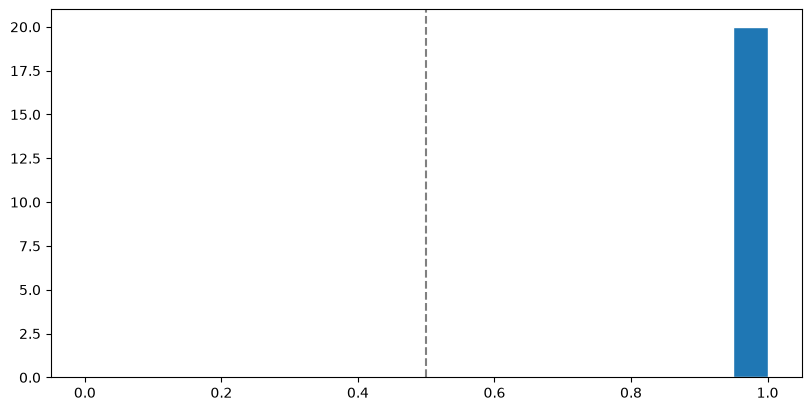

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.hist(model_probs, bins=np.linspace(0, 1, 21), edgecolor="white")
ax.axvline(MODEL_THRESHOLD, color="gray", linestyle="--", label=f"Threshold {MODEL_THRESHOLD:.2f}")
ax.set(xlabel="Pretrained GridSFM P(feasible)", ylabel="Number of candidates",
       title=f"GridSFM model predictions — {DATASET_LABEL}")
ax.legend()
fig.savefig(EXPLAIN_ROOT / "model_feasibility_histogram.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Choose the candidate you want to explain

Use `Predicted feasible`, `Predicted infeasible`, `Near threshold`, high-confidence, or large-perturbation filters. The selected candidate's verdict comes **solely from the pretrained GridSFM checkpoint**. With `ipywidgets` installed, choose from the dropdown and rerun the activation/SHAP cells. Otherwise use `MANUAL_SCENARIO_INDEX`.

In [8]:
FILTERS = [
    "All candidates",
    "Predicted feasible",
    "Predicted infeasible",
    "High confidence feasible (P>=0.9)",
    "High confidence infeasible (P<=0.1)",
    "Near threshold (0.4<=P<=0.6)",
    "Largest Pd perturbations (top 10)",
    "Largest Qd perturbations (top 10)",
]

def matches_model_filter(row, filter_name):
    p = row["gridsfm_p_feasible"]
    if filter_name == "All candidates": return True
    if filter_name == "Predicted feasible": return p >= MODEL_THRESHOLD
    if filter_name == "Predicted infeasible": return p < MODEL_THRESHOLD
    if filter_name == "High confidence feasible (P>=0.9)": return p >= 0.9
    if filter_name == "High confidence infeasible (P<=0.1)": return p <= 0.1
    if filter_name == "Near threshold (0.4<=P<=0.6)": return 0.4 <= p <= 0.6
    if filter_name == "Largest Pd perturbations (top 10)":
        indices = {r["candidate_index"] for r in sorted(model_rows,
                  key=lambda r: r["mean_abs_pd_change"], reverse=True)[:10]}
        return row["candidate_index"] in indices
    if filter_name == "Largest Qd perturbations (top 10)":
        indices = {r["candidate_index"] for r in sorted(model_rows,
                  key=lambda r: r["mean_abs_qd_change"], reverse=True)[:10]}
        return row["candidate_index"] in indices
    raise ValueError(filter_name)

def describe_candidate(row):
    return (f"#{row['candidate_index']:03d} | iter {row['iteration']}, sample {row['scenario']} "
            f"| {row['model_category']} | P(feasible)={row['gridsfm_p_feasible']:.4f}")

def show_candidates(filter_name="All candidates", max_rows=40):
    selected_rows = [r for r in model_rows if matches_model_filter(r, filter_name)]
    print(f"{filter_name}: {len(selected_rows)} candidate(s)")
    for row in selected_rows[:max_rows]: print("  ", describe_candidate(row))
    if len(selected_rows)>max_rows: print("  ... see model predictions CSV for remaining candidates")
    return selected_rows

try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False

if WIDGETS_AVAILABLE:
    FILTER_WIDGET = widgets.Dropdown(options=FILTERS, value="All candidates",
                                     description="Model filter:", layout=widgets.Layout(width="95%"))
    CANDIDATE_WIDGET = widgets.Dropdown(description="Candidate:", layout=widgets.Layout(width="95%"))
    def update_candidate_dropdown(change=None):
        rows = [r for r in model_rows if matches_model_filter(r, FILTER_WIDGET.value)]
        previous = CANDIDATE_WIDGET.value
        CANDIDATE_WIDGET.options = ([(describe_candidate(r), r["candidate_index"]) for r in rows]
                                     if rows else [("No matches: change filter", None)])
        if previous in [r["candidate_index"] for r in rows]:
            CANDIDATE_WIDGET.value = previous
    FILTER_WIDGET.observe(update_candidate_dropdown, names="value")
    update_candidate_dropdown()
    display(widgets.VBox([FILTER_WIDGET, CANDIDATE_WIDGET]))
    print("Choose a candidate, then rerun Activate selected candidate and subsequent SHAP cells.")
else:
    print("No ipywidgets. Edit MANUAL_SCENARIO_INDEX in Activate selected candidate.")
    print("Optional: %pip install ipywidgets")
show_candidates(max_rows=30)

No ipywidgets. Edit MANUAL_SCENARIO_INDEX in Activate selected candidate.
Optional: %pip install ipywidgets
All candidates: 20 candidate(s)
   #000 | iter 1, sample 1 | Predicted feasible | P(feasible)=0.9999
   #001 | iter 1, sample 2 | Predicted feasible | P(feasible)=0.9979
   #002 | iter 2, sample 1 | Predicted feasible | P(feasible)=0.9967
   #003 | iter 2, sample 2 | Predicted feasible | P(feasible)=0.9968
   #004 | iter 3, sample 1 | Predicted feasible | P(feasible)=0.9992
   #005 | iter 3, sample 2 | Predicted feasible | P(feasible)=0.9999
   #006 | iter 4, sample 1 | Predicted feasible | P(feasible)=0.9946
   #007 | iter 4, sample 2 | Predicted feasible | P(feasible)=0.9952
   #008 | iter 5, sample 1 | Predicted feasible | P(feasible)=0.9938
   #009 | iter 5, sample 2 | Predicted feasible | P(feasible)=0.9999
   #010 | iter 6, sample 1 | Predicted feasible | P(feasible)=0.9999
   #011 | iter 6, sample 2 | Predicted feasible | P(feasible)=0.9996
   #012 | iter 7, sample 1 | Pre

[{'candidate_index': 0,
  'iteration': 1,
  'scenario': 1,
  'gridsfm_p_feasible': 0.9999086856842041,
  'gridsfm_p_infeasible': 9.131431579589844e-05,
  'model_category': 'Predicted feasible',
  'mean_abs_pd_change': 0.031196942552924156,
  'mean_abs_qd_change': 0.013288762420415878},
 {'candidate_index': 1,
  'iteration': 1,
  'scenario': 2,
  'gridsfm_p_feasible': 0.9979458451271057,
  'gridsfm_p_infeasible': 0.002054154872894287,
  'model_category': 'Predicted feasible',
  'mean_abs_pd_change': 0.031570468097925186,
  'mean_abs_qd_change': 0.013448856770992279},
 {'candidate_index': 2,
  'iteration': 2,
  'scenario': 1,
  'gridsfm_p_feasible': 0.9966650605201721,
  'gridsfm_p_infeasible': 0.003334939479827881,
  'model_category': 'Predicted feasible',
  'mean_abs_pd_change': 0.0317634679377079,
  'mean_abs_qd_change': 0.013529976829886436},
 {'candidate_index': 3,
  'iteration': 2,
  'scenario': 2,
  'gridsfm_p_feasible': 0.9968411922454834,
  'gridsfm_p_infeasible': 0.003158807754

### Optional: compare **two model predictions** before choosing

This compares only GridSFM's probability scores; it does **not** use Julia's labels. You can skip this section.

A #018 | iter 10, sample 1 | Predicted feasible | P(feasible)=1.0000
B #015 | iter 8, sample 2 | Predicted feasible | P(feasible)=0.9928


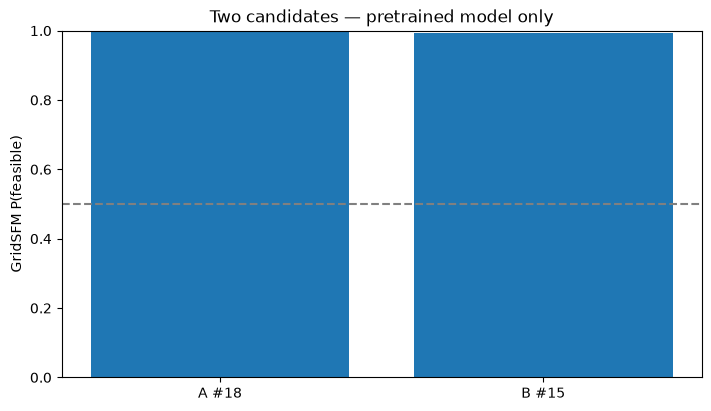

In [9]:
p_desc = sorted(model_rows, key=lambda r:r["gridsfm_p_feasible"], reverse=True)
PAIR_A_INDEX = p_desc[0]["candidate_index"]
PAIR_B_INDEX = p_desc[-1]["candidate_index"]
if WIDGETS_AVAILABLE:
    pair_options = [(describe_candidate(r), r["candidate_index"]) for r in model_rows]
    # Reuse widgets on rerun, so changing A/B actually updates the comparison.
    if "PAIR_A_WIDGET" not in globals() or "PAIR_B_WIDGET" not in globals():
        PAIR_A_WIDGET = widgets.Dropdown(options=pair_options, value=PAIR_A_INDEX,
                                         description="Candidate A:", layout=widgets.Layout(width="95%"))
        PAIR_B_WIDGET = widgets.Dropdown(options=pair_options, value=PAIR_B_INDEX,
                                         description="Candidate B:", layout=widgets.Layout(width="95%"))
        display(widgets.VBox([PAIR_A_WIDGET, PAIR_B_WIDGET]))
    else:
        PAIR_A_WIDGET.options = pair_options
        PAIR_B_WIDGET.options = pair_options
    print("Change A or B above, then rerun this cell to refresh the comparison plot.")
    a_idx, b_idx = int(PAIR_A_WIDGET.value), int(PAIR_B_WIDGET.value)
else:
    a_idx, b_idx = PAIR_A_INDEX, PAIR_B_INDEX
for name, index in [("A",a_idx),("B",b_idx)]:
    print(name, describe_candidate(model_rows[index]))
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.bar([f"A #{a_idx}", f"B #{b_idx}"], [model_probs[a_idx], model_probs[b_idx]])
ax.axhline(MODEL_THRESHOLD, ls="--", color="gray")
ax.set(ylim=(0,1), ylabel="GridSFM P(feasible)", title="Two candidates — pretrained model only")
plt.show()

## 7. Activate a candidate and choose what to explain

`EXPLANATION_TARGET = "predicted"` explains the predicted class: for predicted-feasible candidates it explains `P(feasible)`; for predicted-infeasible candidates it explains `P(infeasible) = 1 − P(feasible)`.

**After changing the dropdown, rerun this cell and all explanation cells below it.**

In [10]:
MANUAL_SCENARIO_INDEX = 0
EXPLANATION_TARGET = "predicted"  # "predicted", "feasible", "infeasible"

if WIDGETS_AVAILABLE:
    if CANDIDATE_WIDGET.value is None:
        raise ValueError("No candidates match this filter. Choose another.")
    SCENARIO_INDEX = int(CANDIDATE_WIDGET.value)
else:
    SCENARIO_INDEX = int(MANUAL_SCENARIO_INDEX)
assert 0 <= SCENARIO_INDEX < len(candidates)
assert EXPLANATION_TARGET in ("predicted", "feasible", "infeasible")

chosen_row = model_rows[SCENARIO_INDEX]
chosen = candidates[SCENARIO_INDEX][pyg_to_notebook_index]
delta = chosen - original
p_selected = float(model_probs[SCENARIO_INDEX])
TARGET_CLASS = ("feasible" if chosen_row["model_category"] == "Predicted feasible" else "infeasible") \
    if EXPLANATION_TARGET == "predicted" else EXPLANATION_TARGET
p_original_target = p_original if TARGET_CLASS == "feasible" else 1.0-p_original
p_selected_target = p_selected if TARGET_CLASS == "feasible" else 1.0-p_selected
feasibility_fn = LoadFeasibilityProbability(TARGET_CLASS).eval()
EXPLAIN_DIR = EXPLAIN_ROOT / f"candidate_{SCENARIO_INDEX:05d}"
EXPLAIN_DIR.mkdir(parents=True, exist_ok=True)
print("Selected:", describe_candidate(chosen_row))
print("GridSFM predicted verdict:", chosen_row["model_category"],
      f"(threshold={MODEL_THRESHOLD:.2f})")
print(f"Explaining GridSFM P({TARGET_CLASS})")
print(f"Original: {p_original_target:.6f} | Candidate: {p_selected_target:.6f}")
print("Mean absolute Pd/Qd changes:", np.abs(delta).mean(axis=0))
print("Saving to:", EXPLAIN_DIR)

Selected: #000 | iter 1, sample 1 | Predicted feasible | P(feasible)=0.9999
GridSFM predicted verdict: Predicted feasible (threshold=0.50)
Explaining GridSFM P(feasible)
Original: 0.999941 | Candidate: 0.999909
Mean absolute Pd/Qd changes: [0.03119695 0.01328876]
Saving to: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_load_centered/alabama/gridsfm_pretrained_bus_shap/candidate_00000


## 8. See what the selected candidate changed and what GridSFM predicts

These are raw changes, not SHAP attributions. A large load change does not automatically imply strong model importance.

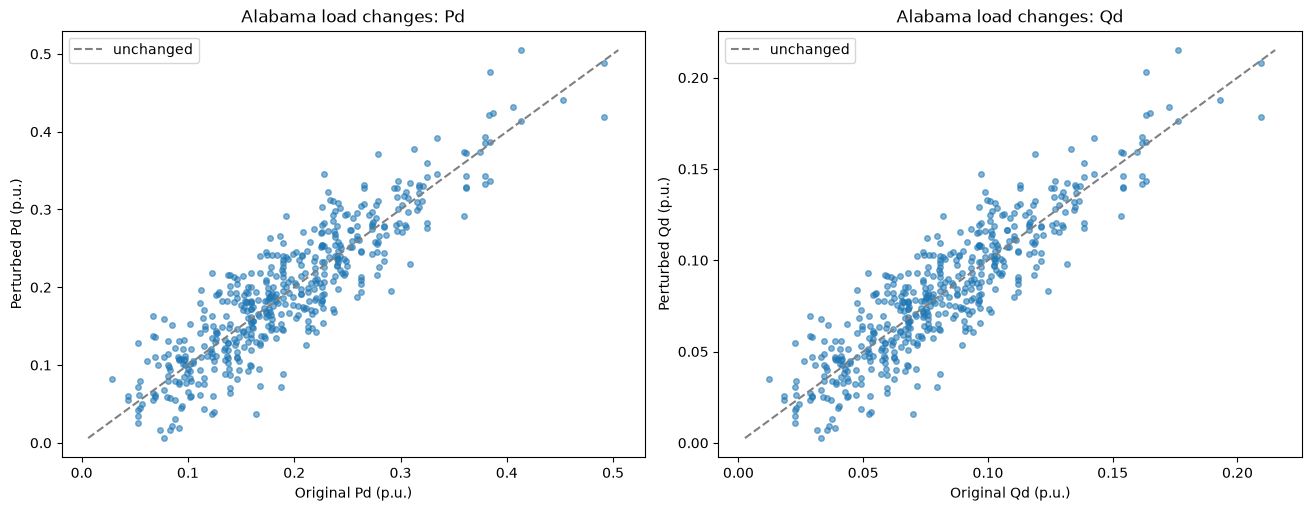

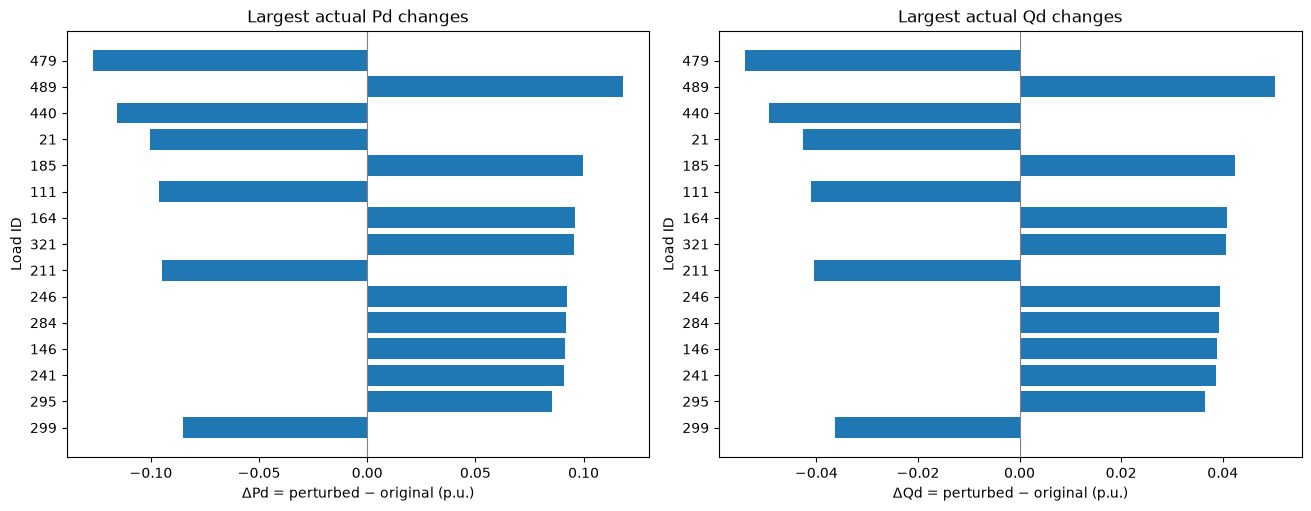

In [11]:
# Plot original vs perturbed values separately for Pd and Qd.
fig, axs = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for j, name in enumerate(("Pd", "Qd")):
    axs[j].scatter(original[:, j], chosen[:, j], s=16, alpha=0.55)
    low = float(min(original[:, j].min(), chosen[:, j].min()))
    high = float(max(original[:, j].max(), chosen[:, j].max()))
    axs[j].plot([low, high], [low, high], ls="--", color="gray", label="unchanged")
    axs[j].set(xlabel=f"Original {name} (p.u.)", ylabel=f"Perturbed {name} (p.u.)",
               title=f"{DATASET_LABEL} load changes: {name}")
    axs[j].legend(loc="best")
fig.savefig(EXPLAIN_DIR / "00_original_vs_perturbed_pd_qd.png", dpi=180, bbox_inches="tight")
fig.savefig(EXPLAIN_DIR / "00_original_vs_perturbed_pd_qd.svg", bbox_inches="tight")
plt.show()

# Most-changed loads, by absolute value within each channel (not model importance).
fig, axs = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for j, name in enumerate(("Pd", "Qd")):
    take = np.argsort(np.abs(delta[:, j]))[-15:][::-1]
    d = delta[take, j][::-1]
    axs[j].barh([str(pyg_load_ids[r]) for r in take[::-1]], d)
    axs[j].axvline(0, color="gray", lw=.8)
    axs[j].set(xlabel=f"Δ{name} = perturbed − original (p.u.)",
               ylabel="Load ID", title=f"Largest actual {name} changes")
fig.savefig(EXPLAIN_DIR / "00_top_load_changes.png", dpi=180, bbox_inches="tight")
plt.show()


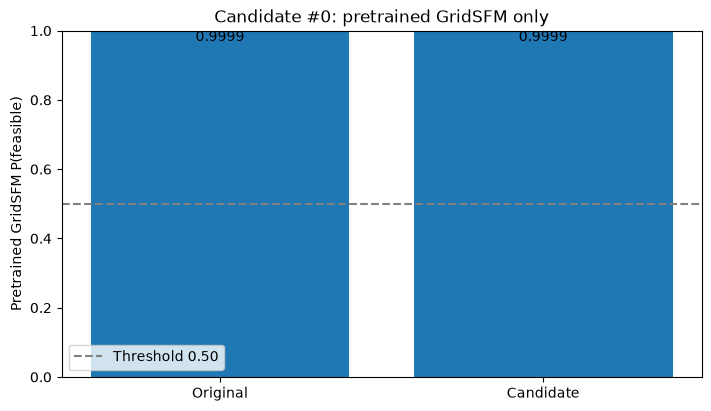

In [12]:
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
vals = [p_original, p_selected]
ax.bar(["Original", "Candidate"], vals)
ax.axhline(MODEL_THRESHOLD, ls="--", color="gray", label=f"Threshold {MODEL_THRESHOLD:.2f}")
ax.set(ylim=(0,1), ylabel="Pretrained GridSFM P(feasible)",
       title=f"Candidate #{SCENARIO_INDEX}: pretrained GridSFM only")
for x, p in enumerate(vals):
    ax.text(x, min(float(p)+.03, .97), f"{p:.4f}", ha="center")
ax.legend()
fig.savefig(EXPLAIN_DIR / "02_model_probability_before_after.png", dpi=180, bbox_inches="tight")
plt.show()

## 9. Global-context group Kernel SHAP: where in the grid does the model focus?

Groups of loads (up to 12 longitude bands, if coordinates are available) are explained jointly for Pd and Qd. **The baseline is the original unperturbed grid.** This stage helps select regions for focused, bus-level SHAP. Group SHAP answers *which groups matter*, **not** which individual bus matters.

In [13]:
N_BANDS = min(12, n_loads)  # Up to 12 nonempty groups for any grid size
N_SHAP_SAMPLES = 64        # Increase for more accurate Kernel SHAP estimates

# Stable ranking avoids empty groups when longitude values tie.
# Without longitude, group PyG rows (a non-geographic fallback).
ordered_rows = (np.argsort(longitudes, kind="stable")
                if longitudes is not None else np.arange(n_loads))
band_idx = np.empty(n_loads, dtype=int)
band_idx[ordered_rows] = (np.arange(n_loads) * N_BANDS) // n_loads
assert band_idx.min() == 0 and band_idx.max() == N_BANDS - 1
assert np.all(np.bincount(band_idx, minlength=N_BANDS) > 0)

# Each group/channel pair is a separate Captum feature.
feature_mask = np.zeros((1, n_loads, 2), dtype=np.int64)
feature_mask[0, :, 0] = 2 * band_idx
feature_mask[0, :, 1] = 2 * band_idx + 1
feature_mask_t = torch.from_numpy(feature_mask)

x_input = torch.tensor(chosen[None, ...], dtype=torch.float32)
x_base = torch.tensor(original[None, ...], dtype=torch.float32)

kernel_shap = KernelShap(feasibility_fn)
shap_t = kernel_shap.attribute(
    x_input, baselines=x_base, feature_mask=feature_mask_t,
    n_samples=N_SHAP_SAMPLES, perturbations_per_eval=1,
    show_progress=True,
)
shap_grid = shap_t.squeeze(0).detach().cpu().numpy()
shap_band = np.array([
    [float(shap_grid[band_idx == g, j].mean()) for j in range(2)]
    for g in range(N_BANDS)
])
# Captum broadcasts a group attribution to all group members;
# averaging recovers the group attribution. Summing would overcount it.
assert np.isfinite(shap_band).all(), "Nonfinite SHAP. Investigate model numerical behavior."
print("Group SHAP shape:", shap_band.shape, "| grouping:", GROUPING_METHOD)
print(f"Positive SHAP: increases GridSFM P({TARGET_CLASS}) vs original loads")
print(f"Negative SHAP: decreases GridSFM P({TARGET_CLASS}) vs original loads")

Kernel Shap attribution: 100%|██████████| 64/64 [00:19<00:00,  3.33it/s]


Group SHAP shape: (12, 2) | grouping: longitude_rank_quantiles
Positive SHAP: increases GridSFM P(feasible) vs original loads
Negative SHAP: decreases GridSFM P(feasible) vs original loads


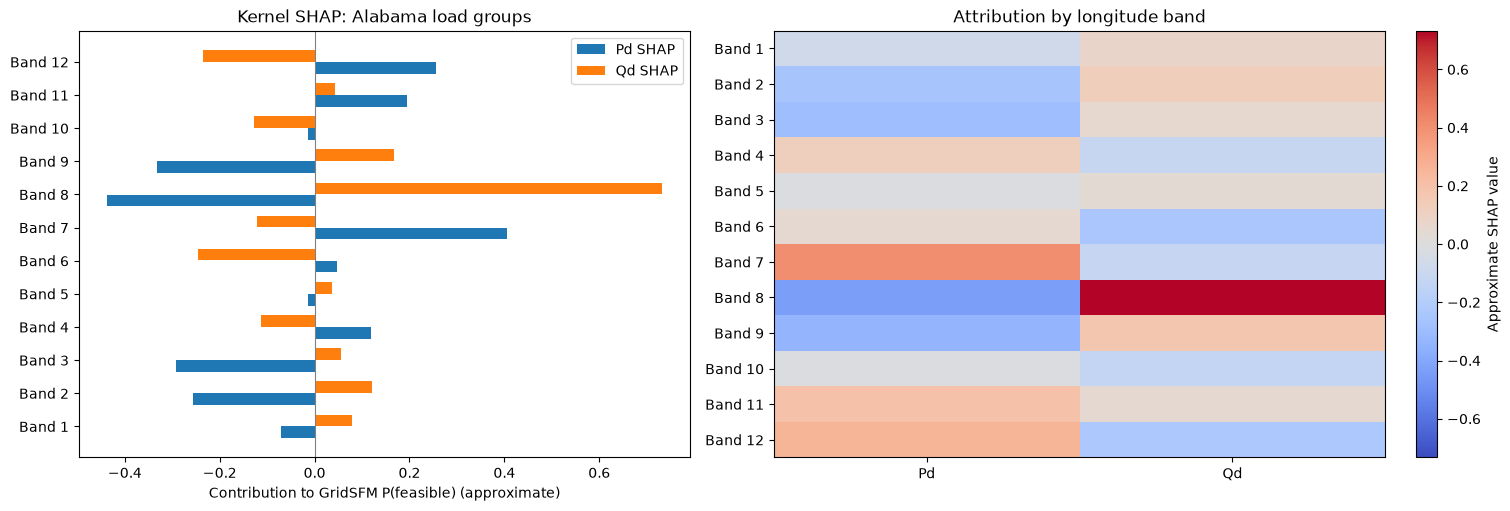

Top groups by |SHAP|:
{'group': 8, 'group_label': 'Band 8', 'grouping_method': 'longitude_rank_quantiles', 'n_loads': 41, 'longitude_min': -86.5572109, 'longitude_max': -86.3462574, 'pd_shap': -0.43855974078178406, 'qd_shap': 0.7330195307731628, 'total_delta_pd_pu': -0.60191810131073, 'total_delta_qd_pu': -0.2565850019454956}
{'group': 7, 'group_label': 'Band 7', 'grouping_method': 'longitude_rank_quantiles', 'n_loads': 42, 'longitude_min': -86.74798225, 'longitude_max': -86.5592619, 'pd_shap': 0.4060242176055908, 'qd_shap': -0.12227045744657516, 'total_delta_pd_pu': 0.5431013107299805, 'total_delta_qd_pu': 0.2313411682844162}
{'group': 9, 'group_label': 'Band 9', 'grouping_method': 'longitude_rank_quantiles', 'n_loads': 41, 'longitude_min': -86.34569146666666, 'longitude_max': -86.0710254, 'pd_shap': -0.3329163193702698, 'qd_shap': 0.16664345562458038, 'total_delta_pd_pu': 0.1641199290752411, 'total_delta_qd_pu': 0.06985557079315186}
{'group': 3, 'group_label': 'Band 3', 'grouping_met

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
ys = np.arange(N_BANDS)
labels = [f"{GROUP_LABEL} {i+1}" for i in ys]
ax1.barh(ys - 0.18, shap_band[:, 0], height=0.35, label="Pd SHAP")
ax1.barh(ys + 0.18, shap_band[:, 1], height=0.35, label="Qd SHAP")
ax1.axvline(0, color="gray", linewidth=0.8)
ax1.set_yticks(ys, labels)
ax1.set_xlabel(f"Contribution to GridSFM P({TARGET_CLASS}) (approximate)")
ax1.set_title(f"Kernel SHAP: {DATASET_LABEL} load groups")
ax1.legend()

vmax = max(float(np.abs(shap_band).max()), 1e-8)
im = ax2.imshow(shap_band, cmap="coolwarm", aspect="auto", vmin=-vmax, vmax=vmax)
ax2.set_xticks([0, 1], ["Pd", "Qd"])
ax2.set_yticks(ys, labels)
ax2.set_title("Attribution by longitude band" if longitudes is not None else
              "Attribution by PyG-row group (non-geographic)")
fig.colorbar(im, ax=ax2, label="Approximate SHAP value")
fig.savefig(EXPLAIN_DIR / "01_group_shap_bar_and_heatmap.png", dpi=180, bbox_inches="tight")
fig.savefig(EXPLAIN_DIR / "01_group_shap_bar_and_heatmap.svg", bbox_inches="tight")
plt.show()

band_table = []
for i in range(N_BANDS):
    members = band_idx == i
    band_table.append({
        "group": i + 1,
        "group_label": f"{GROUP_LABEL} {i+1}",
        "grouping_method": GROUPING_METHOD,
        "n_loads": int(members.sum()),
        "longitude_min": (float(longitudes[members].min()) if longitudes is not None else None),
        "longitude_max": (float(longitudes[members].max()) if longitudes is not None else None),
        "pd_shap": float(shap_band[i, 0]), "qd_shap": float(shap_band[i, 1]),
        "total_delta_pd_pu": float(delta[members, 0].sum()),
        "total_delta_qd_pu": float(delta[members, 1].sum()),
    })
print("Top groups by |SHAP|:")
for entry in sorted(band_table, key=lambda row: max(abs(row["pd_shap"]), abs(row["qd_shap"])),
                    reverse=True)[:8]:
    print(entry)

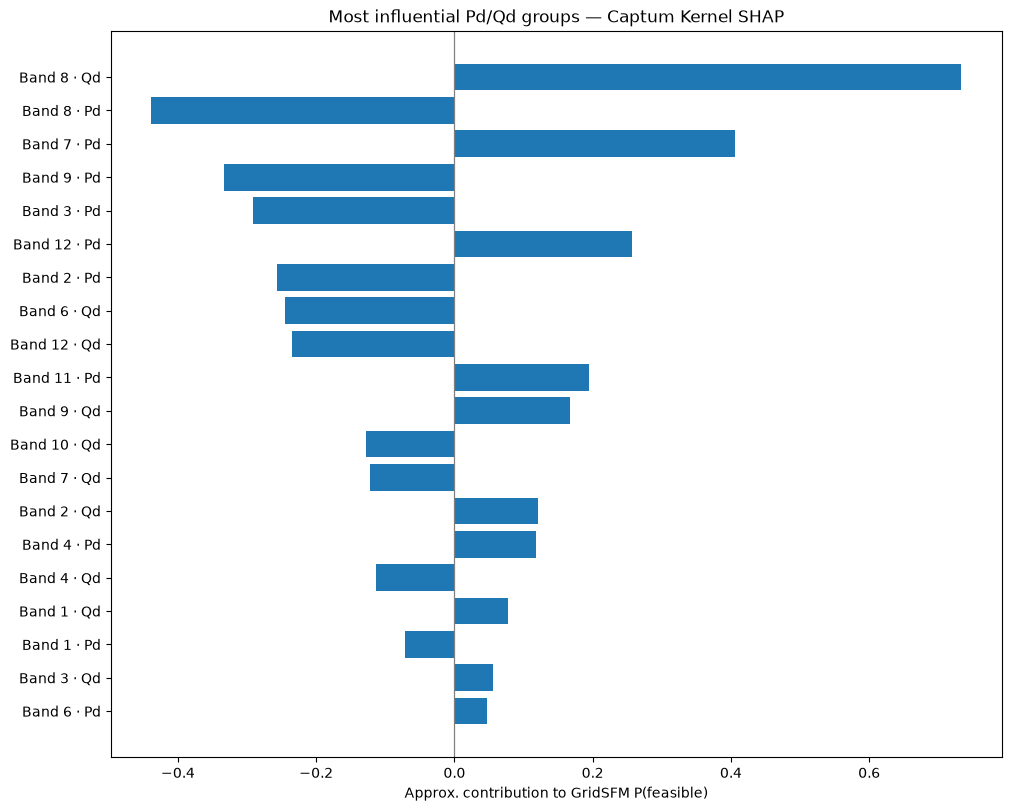

Model P(feasible) difference: -3.3e-05
Sum of group SHAP contributions (approx.): -3.3e-05
Gap (attribution estimate − model difference): -0.0
Total absolute group attribution: Pd= 2.442023 Qd= 2.079074


In [15]:
labels = [f"{GROUP_LABEL} {g+1} · {channel}" for g in range(N_BANDS) for channel in ("Pd", "Qd")]
values = shap_band.reshape(-1)
ranked = np.argsort(np.abs(values))[::-1][:min(20, len(values))]
ranked = ranked[::-1]  # largest magnitudes at the top
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
ax.barh([labels[k] for k in ranked], values[ranked])
ax.axvline(0, lw=.9, color="gray")
ax.set_xlabel(f"Approx. contribution to GridSFM P({TARGET_CLASS})")
ax.set_title("Most influential Pd/Qd groups — Captum Kernel SHAP")
fig.savefig(EXPLAIN_DIR / "03_ranked_group_shap.png", dpi=180, bbox_inches="tight")
fig.savefig(EXPLAIN_DIR / "03_ranked_group_shap.svg", bbox_inches="tight")
plt.show()

print(f"Model P({TARGET_CLASS}) difference:", round(p_selected_target-p_original_target, 6))
print("Sum of group SHAP contributions (approx.):", round(float(values.sum()), 6))
print("Gap (attribution estimate − model difference):", round(float(values.sum()-(p_selected_target-p_original_target)), 6))
print("Total absolute group attribution: Pd=", round(float(np.abs(shap_band[:,0]).sum()),6),
      "Qd=", round(float(np.abs(shap_band[:,1]).sum()),6))

## 10. Bus-level Kernel SHAP — which buses contribute to the GridSFM verdict?

This computes a *second, focused* Kernel SHAP over **selected buses and Pd/Qd channels**. Other candidate loads stay fixed; selected buses are toggled between original and perturbed values. The baseline here is thus **conditional**, not the whole unperturbed grid.

By default, it identifies up to 8 buses from the most influential global groups, ranking candidates inside those groups by perturbation magnitude **before** computing their individual SHAP contributions. Set `MANUAL_BUS_IDS` to override bus selection. **It does not claim global importance for every unselected bus**, and larger SHAP sample counts are more stable but costly.

In [16]:
# Choose at most this many buses for a focused SHAP explanation.
BUS_SHAP_TOP_GROUPS = 2
BUS_SHAP_MAX_BUSES = 8
N_BUS_SHAP_SAMPLES = 128  # Increase (e.g. 512) for more stable bus-level estimates.
MANUAL_BUS_IDS = None     # e.g. ["403", "120"] to study specific buses instead.

assert BUS_SHAP_MAX_BUSES >= 1 and BUS_SHAP_TOP_GROUPS >= 1
assert N_BUS_SHAP_SAMPLES >= 2

from collections import defaultdict
bus_to_pyg_rows = defaultdict(list)
for row_idx, busid in enumerate(pyg_load_bus_id):
    bus_to_pyg_rows[str(busid)].append(int(row_idx))

if MANUAL_BUS_IDS is not None:
    selected_bus_ids = list(dict.fromkeys(str(x) for x in MANUAL_BUS_IDS))
    missing = [b for b in selected_bus_ids if b not in bus_to_pyg_rows]
    if missing:
        raise ValueError(f"Selected bus IDs have no active loads in the matching PyG graph: {missing}")
    if not selected_bus_ids:
        raise ValueError("MANUAL_BUS_IDS cannot be an empty list")
else:
    # SHAP selects influential groups; changes rank buses *within* those groups.
    group_strength = np.max(np.abs(shap_band), axis=1)
    chosen_groups = np.argsort(group_strength)[::-1][:min(BUS_SHAP_TOP_GROUPS, N_BANDS)]
    candidate_rows = np.flatnonzero(np.isin(band_idx, chosen_groups))
    bus_score = defaultdict(float)
    for r in candidate_rows:
        bus_score[pyg_load_bus_id[r]] += float(np.abs(delta[r]).sum())
    selected_bus_ids = [b for b, score in sorted(bus_score.items(), key=lambda x: x[1], reverse=True)
                        ][:BUS_SHAP_MAX_BUSES]

n_selected_buses = len(selected_bus_ids)
print("Bus-level SHAP selected", n_selected_buses, "buses:")
for b in selected_bus_ids:
    name = data["bus"][b].get("name", "")
    print(f"  Bus {b} ({name or 'unnamed'}), active loads={len(bus_to_pyg_rows[b])}")

# One *binary degree of freedom* per selected (bus, channel).
# 1 = candidate's perturbation; 0 = restore original value for that bus/channel.
# All unselected buses stay at the chosen candidate values.
def focused_bus_probability(mask_batch):
    scores = []
    for mask in mask_batch.detach().cpu().numpy():
        test = chosen.copy()
        for k, bus in enumerate(selected_bus_ids):
            rows = bus_to_pyg_rows[bus]
            for j in range(2):
                test[rows, j] = original[rows, j] + mask[k, j] * delta[rows, j]
        p_feasible = grid_probability_pygrid(test)
        scores.append(p_feasible if TARGET_CLASS == "feasible" else 1.0 - p_feasible)
    return torch.tensor(scores, dtype=torch.float32, device=mask_batch.device)

bus_mask_input = torch.ones((1, n_selected_buses, 2), dtype=torch.float32)
bus_mask_baseline = torch.zeros_like(bus_mask_input)
bus_shap = KernelShap(focused_bus_probability).attribute(
    bus_mask_input,
    baselines=bus_mask_baseline,
    n_samples=N_BUS_SHAP_SAMPLES,
    perturbations_per_eval=1,
    show_progress=True,
).squeeze(0).detach().cpu().numpy()
assert bus_shap.shape == (n_selected_buses, 2) and np.isfinite(bus_shap).all()

conditional_original = chosen.copy()
for b in selected_bus_ids:
    r = bus_to_pyg_rows[b]
    conditional_original[r, :] = original[r, :]
p_cond_feasible = grid_probability_pygrid(conditional_original)
p_cond_target = p_cond_feasible if TARGET_CLASS == "feasible" else 1 - p_cond_feasible
print(f"Conditional baseline P({TARGET_CLASS}): {p_cond_target:.6f}")
print(f"Selected candidate P({TARGET_CLASS}): {p_selected_target:.6f}")
print(f"Model difference: {p_selected_target - p_cond_target:+.6f}")
print(f"Sum of focused bus SHAP: {bus_shap.sum():+.6f}")
print(f"SHAP approximation gap: {bus_shap.sum() - (p_selected_target - p_cond_target):+.6f}")

Bus-level SHAP selected 8 buses:
  Bus 258 (South Jefferson Substation), active loads=1
  Bus 307 (East Trussville Substation), active loads=1
  Bus 253 (BUS_253), active loads=1
  Bus 441 (BUS_441), active loads=1
  Bus 26 (Guntersville Dam Substation), active loads=1
  Bus 563 (U S Alliance Coosa Pines Cogen), active loads=1
  Bus 354 (BUS_354), active loads=1
  Bus 5 (Autaugaville 230kV Substation), active loads=1


Kernel Shap attribution: 100%|██████████| 128/128 [00:36<00:00,  3.47it/s]


Conditional baseline P(feasible): 0.999953
Selected candidate P(feasible): 0.999909
Model difference: -0.000044
Sum of focused bus SHAP: -0.000044
SHAP approximation gap: -0.000000



Selected bus-level SHAP for GridSFM P(feasible) (largest |contribution| first):
Bus    354 | BUS_354                    | ΔPd=-0.07164 ΔQd=-0.03051 | Pd SHAP=-0.00178 Qd SHAP=+0.00209 | Sum=+0.00031
Bus    441 | BUS_441                    | ΔPd=-0.08485 ΔQd=-0.03616 | Pd SHAP=+0.00047 Qd SHAP=+0.00021 | Sum=+0.00068
Bus    307 | East Trussville Substation | ΔPd=+0.09206 ΔQd=+0.03922 | Pd SHAP=-0.00042 Qd SHAP=-0.00020 | Sum=-0.00061
Bus    563 | U S Alliance Coosa Pines C | ΔPd=-0.07592 ΔQd=-0.03234 | Pd SHAP=-0.00024 Qd SHAP=+0.00030 | Sum=+0.00005
Bus     26 | Guntersville Dam Substatio | ΔPd=-0.07776 ΔQd=-0.03310 | Pd SHAP=+0.00016 Qd SHAP=-0.00037 | Sum=-0.00021
Bus    258 | South Jefferson Substation | ΔPd=+0.09247 ΔQd=+0.03938 | Pd SHAP=-0.00007 Qd SHAP=-0.00013 | Sum=-0.00020
Bus    253 | BUS_253                    | ΔPd=+0.09089 ΔQd=+0.03870 | Pd SHAP=-0.00006 Qd SHAP=-0.00012 | Sum=-0.00018
Bus      5 | Autaugaville 230kV Substat | ΔPd=+0.07120 ΔQd=+0.03033 | Pd SHAP=+0.00009

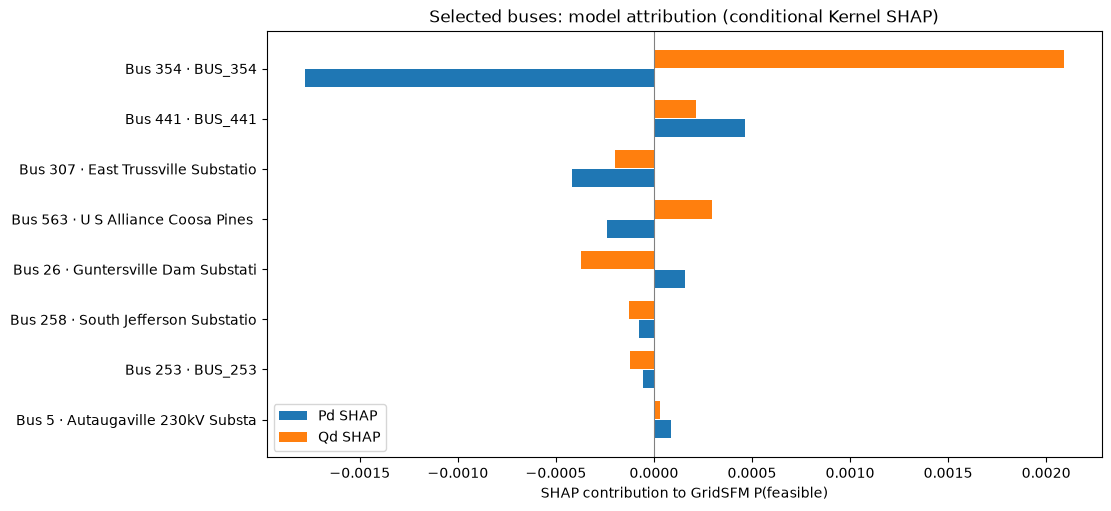

In [17]:
bus_table = []
for k, b in enumerate(selected_bus_ids):
    rows = np.asarray(bus_to_pyg_rows[b], dtype=int)
    bus_table.append({
        "bus_id": str(b),
        "bus_name": str(data["bus"][b].get("name", "")),
        "n_active_loads": int(len(rows)),
        "load_ids": ",".join(pyg_load_ids[r] for r in rows),
        "delta_pd_pu": float(delta[rows, 0].sum()),
        "delta_qd_pu": float(delta[rows, 1].sum()),
        "pd_shap": float(bus_shap[k, 0]),
        "qd_shap": float(bus_shap[k, 1]),
        "total_shap": float(bus_shap[k].sum()),
        "absolute_shap": float(np.abs(bus_shap[k]).sum()),
    })
bus_table.sort(key=lambda x: x["absolute_shap"], reverse=True)

print(f"\nSelected bus-level SHAP for GridSFM P({TARGET_CLASS}) (largest |contribution| first):")
for r in bus_table:
    print(f"Bus {r['bus_id']:>6s} | {r['bus_name'][:26]:26s} | ΔPd={r['delta_pd_pu']:+.5f} "
          f"ΔQd={r['delta_qd_pu']:+.5f} | Pd SHAP={r['pd_shap']:+.5f} "
          f"Qd SHAP={r['qd_shap']:+.5f} | Sum={r['total_shap']:+.5f}")

ordered = list(reversed(bus_table))
fig, ax = plt.subplots(figsize=(11, max(5, len(ordered) * 0.55)), constrained_layout=True)
y = np.arange(len(ordered))
ax.barh(y - 0.19, [r["pd_shap"] for r in ordered], height=0.36, label="Pd SHAP")
ax.barh(y + 0.19, [r["qd_shap"] for r in ordered], height=0.36, label="Qd SHAP")
ax.set_yticks(y, [f"Bus {r['bus_id']} · {r['bus_name'][:25]}" for r in ordered])
ax.axvline(0, color="gray", linewidth=0.8)
ax.set(xlabel=f"SHAP contribution to GridSFM P({TARGET_CLASS})",
       title="Selected buses: model attribution (conditional Kernel SHAP)")
ax.legend()
fig.savefig(EXPLAIN_DIR / "04_selected_bus_kernelshap.png", dpi=180, bbox_inches="tight")
plt.show()

## 11. Export the selected candidate and bus explanations

Outputs include `pretrained_model_predictions.csv` for **all candidates**, and a separate folder for the selected candidate with group-level and selected-bus SHAP CSVs, plots, and a summary JSON. The CSV bus IDs/names let you cite specific buses in your research report.

In [18]:
def write_csv(path, records):
    if not records:
        return
    with Path(path).open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(records[0].keys()))
        writer.writeheader()
        writer.writerows(records)

write_csv(EXPLAIN_DIR / "group_pd_qd_kernelshap.csv", band_table)
write_csv(EXPLAIN_DIR / "selected_bus_pd_qd_kernelshap.csv", bus_table)

summary = {
    "dataset_name": DATASET_NAME,
    "time_slice": TIME_SLICE,
    "raw_case_sha256": CASE_SHA256,
    "sampled_file": str(SCENARIO_PATH),
    "checkpoint": str(CHECKPOINT_PATH),
    "pyg_case": str(PYG_PATH),
    "candidate_index_zero_based": int(SCENARIO_INDEX),
    "iteration": int(saved_iteration[SCENARIO_INDEX]),
    "scenario": int(saved_scenario[SCENARIO_INDEX]),
    "model_threshold": float(MODEL_THRESHOLD),
    "model_prediction": chosen_row["model_category"],
    "model_p_feasible": float(p_selected),
    "model_original_p_feasible": float(p_original),
    "explanation_target": TARGET_CLASS,
    "group_shap_method": f"Captum KernelShap, {GROUPING_METHOD}, original-grid baseline",
    "bus_shap_method": "Captum KernelShap, selected bus/channel toggles, other loads fixed at candidate",
    "bus_shap_conditional_baseline_target_probability": float(p_cond_target),
    "bus_shap_selected_target_probability": float(p_selected_target),
    "bus_shap_samples": int(N_BUS_SHAP_SAMPLES),
    "group_shap_samples": int(N_SHAP_SAMPLES),
    "selected_bus_ids": selected_bus_ids,
    "interpretation": "SHAP describes GridSFM model behavior, not proof of physical AC-OPF feasibility or causation",
}
with (EXPLAIN_DIR / "run_summary.json").open("w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
print("\nSaved:", EXPLAIN_DIR)
print(" - group_pd_qd_kernelshap.csv")
print(" - selected_bus_pd_qd_kernelshap.csv")
print(" - 04_selected_bus_kernelshap.png")
print(" - run_summary.json")


Saved: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_load_centered/alabama/gridsfm_pretrained_bus_shap/candidate_00000
 - group_pd_qd_kernelshap.csv
 - selected_bus_pd_qd_kernelshap.csv
 - 04_selected_bus_kernelshap.png
 - run_summary.json


## Interpretation and limitations

- **Model predicts feasible:** `P(feasible) ≥ MODEL_THRESHOLD`; with `EXPLANATION_TARGET="predicted"`, positive SHAP means that the selected bus/channel pushes the model toward **feasible** relative to the specified baseline.
- **Model predicts infeasible:** `P(feasible) < MODEL_THRESHOLD`; the explained target changes to `P(infeasible)=1-P(feasible)` and positive SHAP now pushes the model toward **infeasible**.
- **Group-level Kernel SHAP:** uses a global original-load baseline and 12 geographic groups (or graph-row groups if longitude is unavailable). **Focused bus-level Kernel SHAP:** compares individual selected bus/channel perturbations while other candidate loads remain fixed. The two SHAP sets answer different questions and should not be summed together.
- Bus ranks apply **only to the selected buses**, not to all buses in the grid. To inspect a specific bus, set `MANUAL_BUS_IDS` and rerun the bus-level section.
- SHAP explains pretrained GridSFM's predictions. It **does not explain Julia's optimization, establish physical infeasibility, or prove causal effects**.
- If the dropdown is missing, install `ipywidgets`, or set `MANUAL_SCENARIO_INDEX` and rerun the activation and explanation cells.
- Re-check input units, exact PyG ID mappings, applicable checkpoint grid sizes, and attribution stability before drawing research conclusions.
